# Simulation of the Convolution of Neutron spectrum and Chopper opening function
Create increasingly difficult neutron spectra  
Create increasingly difficult chopper functions  
Convolute the functions  
Compare the outputs of the convoluted functions to the output of approximations

In [ ]:
import numpy as np
from matplotlib import pyplot as plt


from tof_helper_functions.tof_framework import RawTOFPointList, RebinnedTOFPointList
from tof_helper_functions.tof_simulation_objects import Chopper, Detector
#plt.style.use('stylesheet.mplstyle')

In [28]:
def maxwell(x,a,sigma):
    return a * x**2 / sigma**3 *np.exp(-(x)**2/(2*sigma**2))

In [29]:
n = 4000
n_max =  n-1
maxwell_a = 1000000
x_maxwell_list = np.linspace(0,n_max,n)

# chopper cycle open for 20 m and close for 380 ms
chopper_cycle_time_ms = 400
chopper_open_time_ms = 20
num_chop = 747 # found to have good numerical stability with medium runtime

ONE_SIGMA = 0.6827
t_convolution_offset_err_multiplikator = 1.0
t_convolution_offset = chopper_open_time_ms / 2.0
t_convolution_offset_err = t_convolution_offset * t_convolution_offset_err_multiplikator*ONE_SIGMA

v_low_gaussfit, v_high_gaussfit = 6.0, 11.0

maxwell_sigma_low = 200
maxwell_sigma_high = 550 # for values >550 the gaussian peak fit does not converge
maxwell_sigma_n = 20

maxwell_parameter_sigma_list = np.linspace(maxwell_sigma_low, maxwell_sigma_high, maxwell_sigma_n)
print(maxwell_parameter_sigma_list)
print(f"expected simulation time: {np.sum(num_chop*len(maxwell_parameter_sigma_list))/6500.0:.2f} min")

[200.         218.42105263 236.84210526 255.26315789 273.68421053
 292.10526316 310.52631579 328.94736842 347.36842105 365.78947368
 384.21052632 402.63157895 421.05263158 439.47368421 457.89473684
 476.31578947 494.73684211 513.15789474 531.57894737 550.        ]
expected simulation time: 2.30 min


In [30]:
v_peak_difference_in_sigmas_noeep_list = []
v_peak_difference_in_sigmas_eep_list = []
v_mean_difference_in_sigmas_noeep_list = []
v_mean_difference_in_sigmas_eep_list = []
v_rms_difference_in_sigmas_noeep_list = []
v_rms_difference_in_sigmas_eep_list = []

v_peak_relative_err_list = []
v_mean_relative_err_list = []
v_rms_relative_err_list = []

for maxwell_sigma in maxwell_parameter_sigma_list:

    

    # generate maxwellian spectrum N(bin)
    maxwell_signal_list = maxwell(x_maxwell_list, maxwell_a, maxwell_sigma)

    # feed the maxwellian signal into the TOF framework
    rawTOF_maxwellian = RawTOFPointList(maxwell_signal_list, 
                            s=631, 
                            label = "Poissonian")
    v_max = 18.5
    v_min = 3.5
    v_step = 0.05
    rebinnedTOF_maxwellian = RebinnedTOFPointList(rawTOF_maxwellian,
                                    v_min = v_min,
                                    v_max = v_max,
                                    v_step = v_step,
                                    label = "Rebinned Maxwellian")


    chopper1 = Chopper("Chopper 1", num_chop=num_chop, t_open_ms=chopper_open_time_ms, t_close_ms=chopper_cycle_time_ms-chopper_open_time_ms)
    chopper1.renormalize_opening_function()

    # detector
    detector1 = Detector(num_bins=4000, 
                        s_mm=639, 
                        do_cycle=False,
                        do_gaussian_noise=True,
                        sigma = 50)
    detector1.measure(rawTOF_maxwellian, chopper1)

    rawTOF_maxwellian_convoluted = RawTOFPointList(detector1.data, 
                            s=631, 
                            label = "Convoluted",
                            convolution_t=t_convolution_offset)

    rebinnedTOF_maxwellian_convoluted = RebinnedTOFPointList(rawTOF_maxwellian_convoluted,
                                    v_min = v_min,
                                    v_max = v_max,
                                    v_step = v_step,
                                    label = "Rebinned convoluted")

    rawTOF_maxwellian_convoluted_eep = RawTOFPointList(detector1.data, 
                            s=631, 
                            label = "Convoluted, eep",
                            convolution_t=t_convolution_offset,
                            convolution_t_err=t_convolution_offset_err)

    rebinnedTOF_maxwellian_convoluted_eep = RebinnedTOFPointList(rawTOF_maxwellian_convoluted_eep,
                                    v_min = v_min,
                                    v_max = v_max,
                                    v_step = v_step,
                                    label = "Rebinned convoluted, eep")

    # analyze the pure spectrum and the spectrum after convolution by fitting a gauss to the peak
    v_peak_maxwell, v_peak_maxwell_err = rebinnedTOF_maxwellian.find_peak_velocity(gausstype='threepoints', 
                                                                            v_low=v_low_gaussfit, 
                                                                            v_high=v_high_gaussfit, 
                                                                            a0 = 250000.0, 
                                                                            mu0= 8.0, 
                                                                            sigma0=1.0)
    v_peak_convoluted, v_peak_convoluted_err = rebinnedTOF_maxwellian_convoluted.find_peak_velocity(gausstype='threepoints', 
                                                                                            v_low=v_low_gaussfit, 
                                                                                            v_high=v_high_gaussfit, 
                                                                                            a0 = 250000.0, 
                                                                                            mu0= 8.0, 
                                                                                            sigma0=1.0)
    v_peak_convoluted_eep, v_peak_convoluted_eep_err = rebinnedTOF_maxwellian_convoluted_eep.find_peak_velocity(gausstype='threepoints', 
                                                                                            v_low=v_low_gaussfit, 
                                                                                            v_high=v_high_gaussfit, 
                                                                                            a0 = 250000.0, 
                                                                                            mu0= 8.0, 
                                                                                            sigma0=1.0)

    v_mean_maxwell, v_mean_maxwell_err = rebinnedTOF_maxwellian.find_mean_velocity()
    v_mean_convoluted, v_mean_convoluted_err = rebinnedTOF_maxwellian_convoluted.find_mean_velocity()
    v_mean_convoluted_eep, v_mean_convoluted_eep_err = rebinnedTOF_maxwellian_convoluted_eep.find_mean_velocity()

    v_rms_maxwell, v_rms_maxwell_err = rebinnedTOF_maxwellian.find_rms_velocity()
    v_rms_convoluted, v_rms_convoluted_err = rebinnedTOF_maxwellian_convoluted.find_rms_velocity()
    v_rms_convoluted_eep, v_rms_convoluted_eep_err = rebinnedTOF_maxwellian_convoluted_eep.find_rms_velocity()

    v_peak_relative_err_list.append(v_peak_convoluted_eep_err / v_peak_convoluted_eep)
    v_mean_relative_err_list.append(v_mean_convoluted_eep_err / v_mean_convoluted_eep)
    v_rms_relative_err_list.append(v_rms_convoluted_eep_err / v_rms_convoluted_eep)

    v_peak_difference_in_sigmas_noeep_list.append(np.abs(v_peak_maxwell - v_peak_convoluted) / np.sqrt(v_peak_maxwell_err**2 + v_peak_convoluted_err**2))
    v_peak_difference_in_sigmas_eep_list.append(np.abs(v_peak_maxwell - v_peak_convoluted_eep) / np.sqrt(v_peak_maxwell_err**2 + v_peak_convoluted_eep_err**2))

    v_mean_difference_in_sigmas_noeep_list.append(np.abs(v_mean_maxwell - v_mean_convoluted) / np.sqrt(v_mean_maxwell_err**2 + v_mean_convoluted_err**2))
    v_mean_difference_in_sigmas_eep_list.append(np.abs(v_mean_maxwell - v_mean_convoluted_eep) / np.sqrt(v_mean_maxwell_err**2 + v_mean_convoluted_eep_err**2))

    v_rms_difference_in_sigmas_noeep_list.append(np.abs(v_rms_maxwell - v_rms_convoluted) / np.sqrt(v_rms_maxwell_err**2 + v_rms_convoluted_err**2))
    v_rms_difference_in_sigmas_eep_list.append(np.abs(v_rms_maxwell - v_rms_convoluted_eep) / np.sqrt(v_rms_maxwell_err**2 + v_rms_convoluted_eep_err**2))

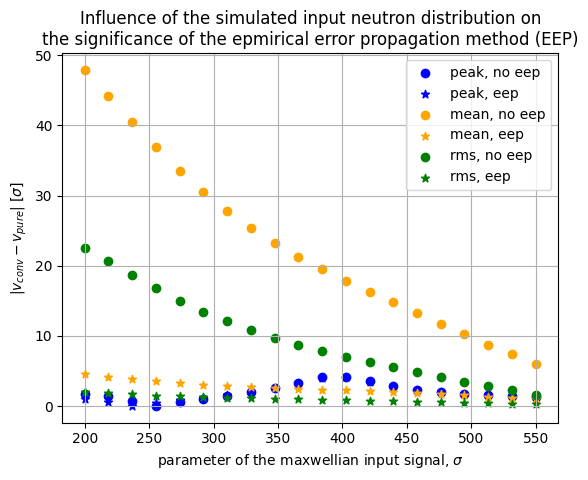

In [35]:
x = maxwell_parameter_sigma_list
xlabel = r"parameter of the maxwellian input signal, $\sigma$"
plt.scatter(x, v_peak_difference_in_sigmas_noeep_list, label="peak, no eep", color="b")
plt.scatter(x, v_peak_difference_in_sigmas_eep_list, label="peak, eep", color="b", marker='*')
plt.scatter(x, v_mean_difference_in_sigmas_noeep_list, label="mean, no eep", color="orange")
plt.scatter(x, v_mean_difference_in_sigmas_eep_list, label="mean, eep", color="orange", marker='*')
plt.scatter(x, v_rms_difference_in_sigmas_noeep_list, label="rms, no eep", color="g")
plt.scatter(x, v_rms_difference_in_sigmas_eep_list, label="rms, eep", color="g", marker='*')
plt.xlabel(xlabel)
plt.ylabel(r"|$v_{conv}-v_{pure}$| [$\sigma$]")
plt.legend()
plt.grid(True)
plt.title(f"Influence of the simulated input neutron distribution on\nthe significance of the epmirical error propagation method (EEP)")
plt.show()

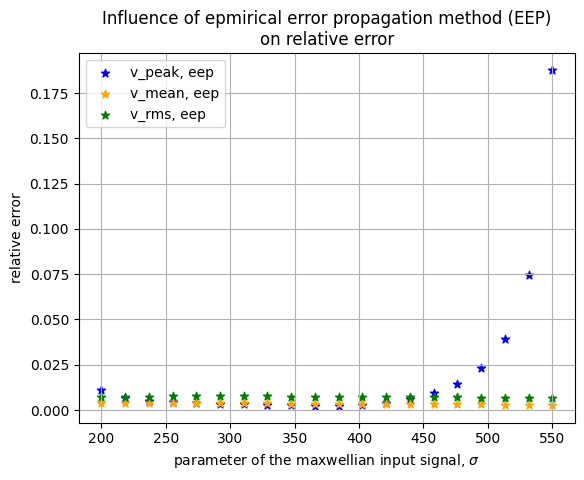

In [37]:
plt.scatter(x, v_peak_relative_err_list, label="v_peak, eep", color="b", marker='*')
plt.scatter(x, v_mean_relative_err_list, label="v_mean, eep", color="orange", marker='*')
plt.scatter(x, v_rms_relative_err_list, label="v_rms, eep", color="g", marker='*')
plt.xlabel(xlabel)
plt.ylabel("relative error")
plt.legend()
plt.grid(True)
plt.title(f"Influence of epmirical error propagation method (EEP)\non relative error")
plt.show()

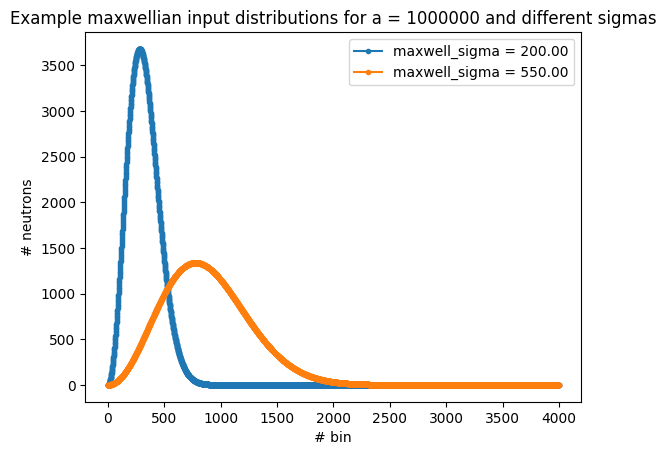

In [38]:
# print two example input spectra
plt.plot(x_maxwell_list, maxwell(x_maxwell_list, maxwell_a, maxwell_parameter_sigma_list[0]), marker='.', label=f"maxwell_sigma = {maxwell_parameter_sigma_list[0]:.2f}") 
plt.plot(x_maxwell_list, maxwell(x_maxwell_list, maxwell_a, maxwell_parameter_sigma_list[maxwell_sigma_n-1]), marker='.', label=f"maxwell_sigma = {maxwell_parameter_sigma_list[maxwell_sigma_n-1]:.2f}") 
plt.xlabel("# bin")
plt.ylabel("# neutrons")
plt.title(f"Example maxwellian input distributions for a = {maxwell_a} and different sigmas")
plt.legend()
plt.show()